# 18 — MLP Classifier (Multi-Layer Perceptron)

**Algorithm:** MLPClassifier — feedforward neural network (256→128 hidden units)  
**Features:** TF-IDF (50K unigrams + bigrams)  
sklearn's MLP is a fully connected neural network trained with backpropagation. The `loss_curve_` attribute gives a direct epoch-by-epoch convergence trace.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Model Training

In [3]:
from sklearn.neural_network import MLPClassifier
MODEL_NAME = 'MLP Classifier'
model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    max_iter=100,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    verbose=False
)
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')
print(f'Iterations run : {model.n_iter_}')
print(f'Best val score : {model.best_validation_score_:.4f}')

Training completed in 1052.16s
Iterations run : 8
Best val score : 0.8365


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  MLP Classifier — Evaluation Results
  Accuracy          : 0.8325
  Precision         : 0.8339
  Recall            : 0.8325
  F1 Score          : 0.8297
  AUC-ROC           : 0.9271
  Train Time (s)    : 1052.16s

              precision    recall  f1-score   support

    Fake (0)       0.85      0.72      0.78      8532
    Real (1)       0.82      0.91      0.87     12373

    accuracy                           0.83     20905
   macro avg       0.84      0.81      0.82     20905
weighted avg       0.83      0.83      0.83     20905



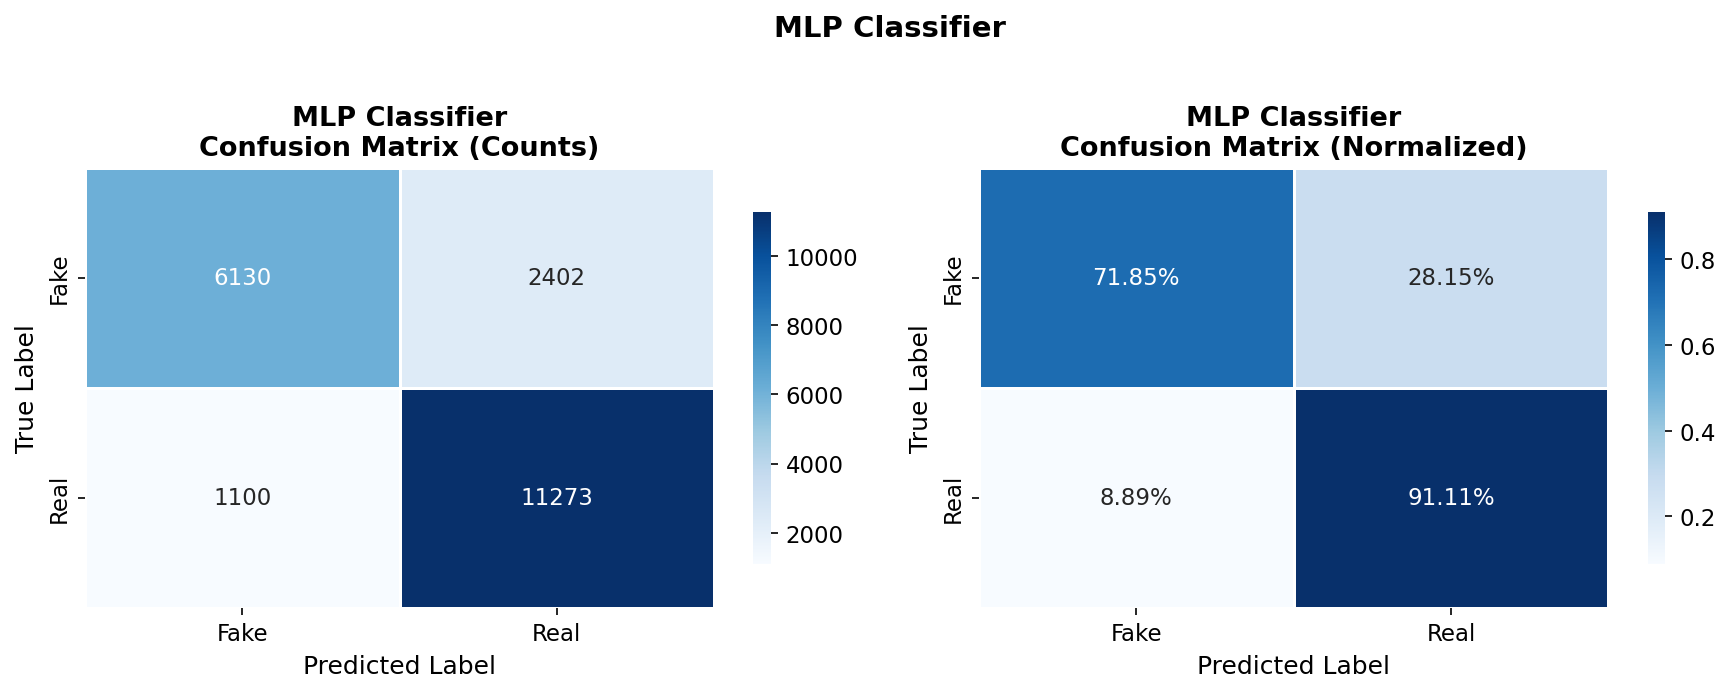

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

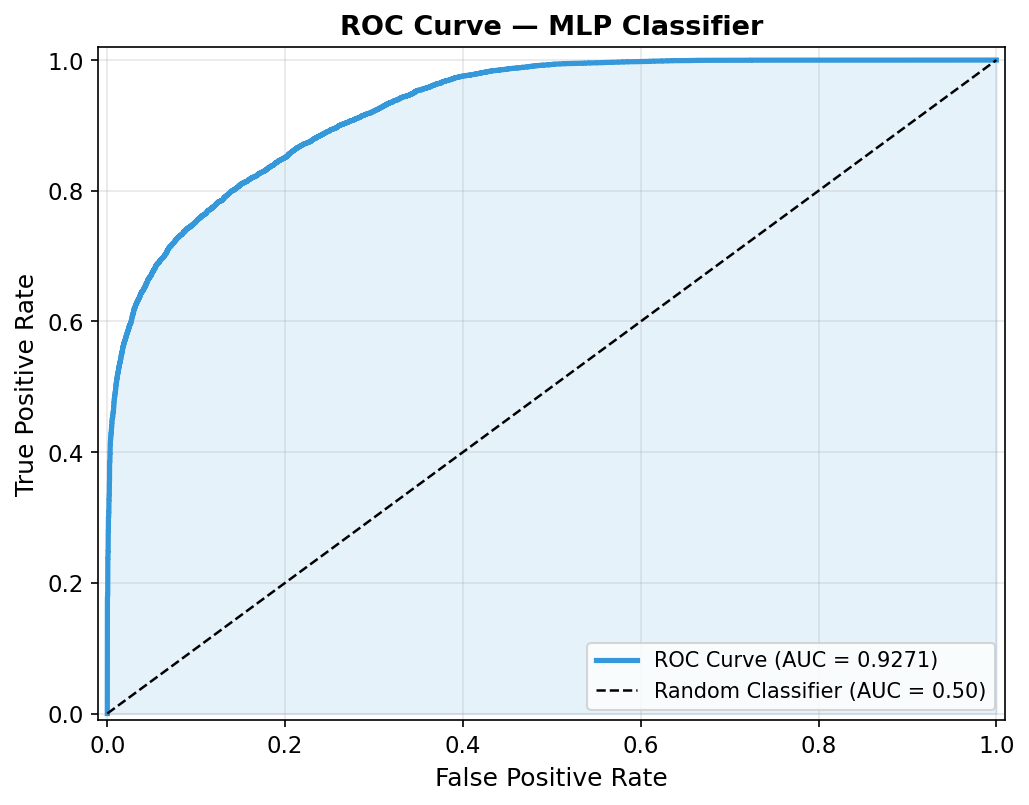

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

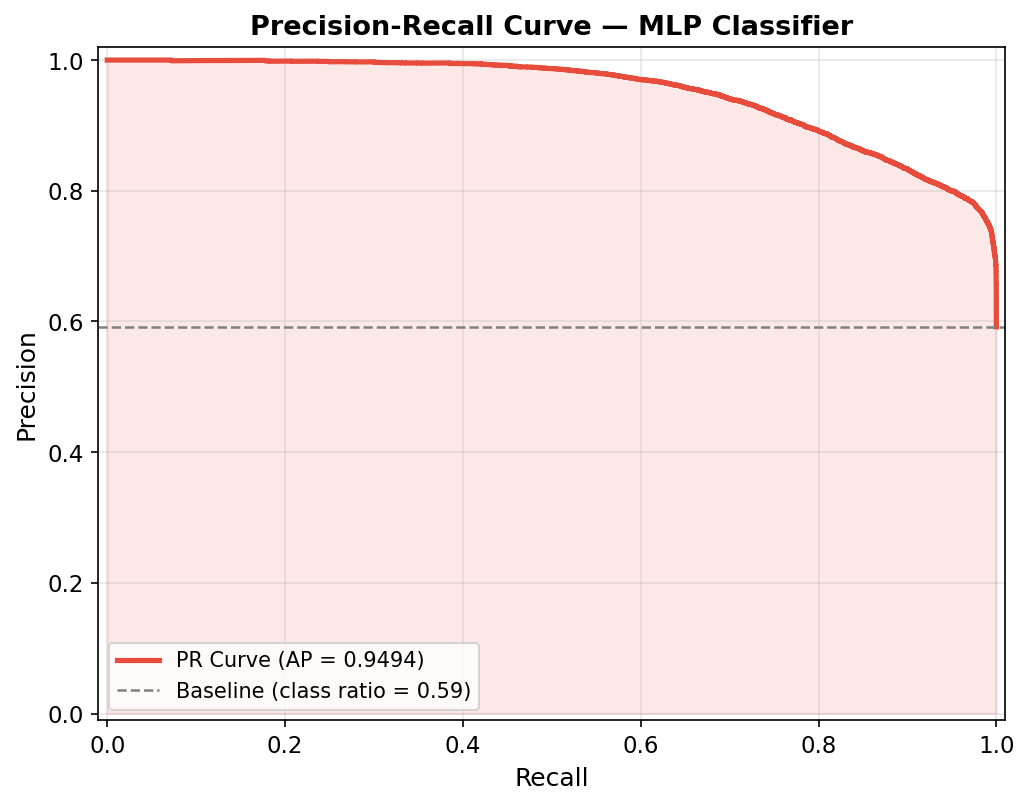

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Training Convergence: Loss & Validation Score per Epoch

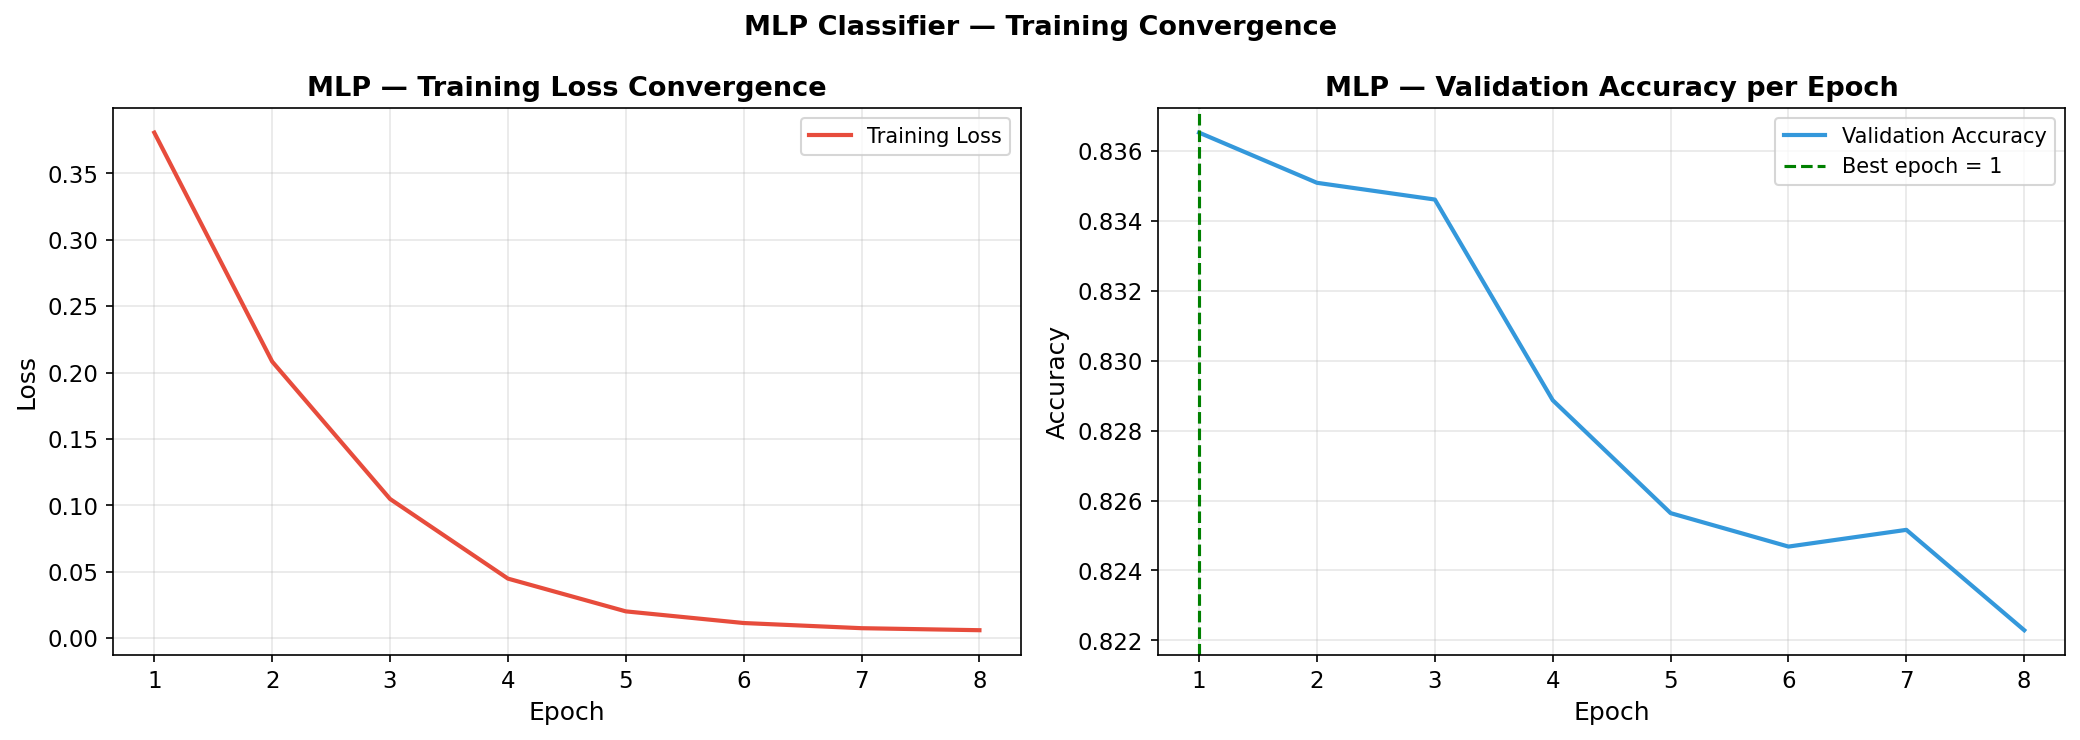

In [8]:
loss_curve = model.loss_curve_
val_scores  = model.validation_scores_
epochs = np.arange(1, len(loss_curve) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs, loss_curve, color='#e74c3c', lw=2, label='Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('MLP — Training Loss Convergence')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

# Validation accuracy
axes[1].plot(np.arange(1, len(val_scores)+1), val_scores,
             color='#3498db', lw=2, label='Validation Accuracy')
best_ep = np.argmax(val_scores) + 1
axes[1].axvline(best_ep, color='green', linestyle='--', lw=1.5,
               label=f'Best epoch = {best_ep}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('MLP — Validation Accuracy per Epoch')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.suptitle('MLP Classifier — Training Convergence', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'mlp_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()